<a href="https://colab.research.google.com/github/Pamodya-Wijesinghe/EN3160-Assignment-2-on-Fitting-and-Alignment/blob/main/EN3160_Assignment_02_230727P.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# EN3160 - Image Processing and Machine Vision
## Assignment 02: Fitting and Alignment

**Name:** Wijesinghe W. A. P. W.  
**Index number:** 230727P  
**Module:** EN3160 - Image Processing and Machine Vision  
**GitHub repository:** [https://github.com/Pamodya-Wijesinghe/EN3160-Assignment-2-on-Fitting-and-Alignment](https://github.com/Pamodya-Wijesinghe/EN3160-Assignment-2-on-Fitting-and-Alignment)


In [1]:
from pathlib import Path
import os
import json
import base64
import cv2 as cv
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter, gaussian_laplace, maximum_filter
from scipy.optimize import minimize
from IPython.display import display, Image

try:
    from google.colab import drive, output
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    drive.mount('/content/drive')
    project_dir = Path('/content/drive/MyDrive/EN3160_Assignment_02')
else:
    project_dir = Path(os.environ.get('EN3160_PROJECT_DIR', '/mnt/data/EN3160_Project_Test'))

images_dir = project_dir / 'images'
results_dir = project_dir / 'results'
results_dir.mkdir(parents=True, exist_ok=True)
assert images_dir.is_dir(), f'Cannot find the images folder: {images_dir}'

required_images = [
    'the_berry_farms_sunflower_field.jpeg', 'building_1.jpg', 'building_2.jpg',
    'AECC1.jpg', 'AECC2.jpg', 'AECC3.jpg', 'AECC4.jpg', 'ADAD1.jpg', 'AAAA1.jpg'
]
missing = [name for name in required_images if not (images_dir / name).exists()]
if missing:
    raise FileNotFoundError('Missing input images: ' + ', '.join(missing))

print('OpenCV:', cv.__version__)
print('Project:', project_dir)
print('Output folder:', results_dir)
print('All input images found:', len(required_images))

Mounted at /content/drive
OpenCV: 5.0.0
Project: /content/drive/MyDrive/EN3160_Assignment_02
Output folder: /content/drive/MyDrive/EN3160_Assignment_02/results
All input images found: 9


---
# Question 1 - Blob detection in the sunflower field

### Method
I load the picture at one-quarter size, as stated in the assignment. A sunflower usually has a dark center surrounded by yellow petals. To reduce false circles in the sky and leaves, I use the grayscale intensity and nearby yellow pixels to make a flower-response image. I then apply the **scale-normalized LoG** at different values of $\sigma$ and find local maxima in the 3D space $(x,y,\sigma)$.

The scale-normalized LoG response is

$$L(x,y,\sigma)=\sigma^2\nabla^2\big(G_\sigma * I\big)(x,y).$$

The blob radius is $r_{\mathrm{LoG}}=\sqrt{2}\sigma$. The outer circle I draw uses $r_{\mathrm{draw}}=1.85r_{\mathrm{LoG}}$, because I want the display circle to cover more of the petals. The factor 1.85 is my visual adjustment, **not** the theoretical LoG radius.

I use **48 scales from $\sigma=0.9$ to $15.0$ pixels**, spaced geometrically. This section uses LoG and scale-space extrema rather than the Hough circle function.

Reduced image dimensions: (360, 360)
Sigma range: 0.9 to 15.0
LoG scale-space candidates surviving flower validation: 258
Accepted circles after duplicate suppression: 207
Largest-circle parameters:
  x   y  sigma  log_blob_radius  display_radius
281 336   8.24            11.66           21.57
105 255   6.49             9.18           16.98
178 260   6.11             8.64           15.99
179 329   6.11             8.64           15.99
273 257   5.11             7.22           13.36
161 290   4.53             6.41           11.85
189 240   4.53             6.41           11.85
 63 243   4.53             6.41           11.85
 70 286   4.27             6.03           11.16
 19 249   4.27             6.03           11.16
Results saved to: /content/drive/MyDrive/EN3160_Assignment_02/results


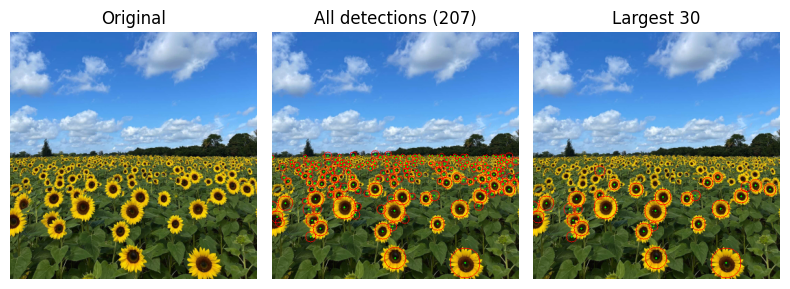

In [2]:
image_path = images_dir / 'the_berry_farms_sunflower_field.jpeg'
# Read at quarter size.
im = cv.imread(str(image_path), cv.IMREAD_REDUCED_COLOR_4)
if im is None:
    raise FileNotFoundError(f'Could not read {image_path}')
H, W = im.shape[:2]
gray = cv.cvtColor(im, cv.COLOR_BGR2GRAY).astype(np.float32) / 255.0
hsv = cv.cvtColor(im, cv.COLOR_BGR2HSV)

# The yellow mask is only an aid to select flowers. Circle candidates
# are still generated through scale-normalized LoG + scale-space extrema.
yellow = ((hsv[:, :, 0] > 13) & (hsv[:, :, 0] < 40) &
          (hsv[:, :, 1] > 90) & (hsv[:, :, 2] > 75)).astype(np.float32)
nearby_yellow = np.maximum(gaussian_filter(yellow, 3),
                           gaussian_filter(yellow, 7))

# High response where the pixel is dark but yellow petals are nearby.
flower_response = np.maximum(0.0, 0.78-gray) * nearby_yellow

# Scale-normalized Laplacian of Gaussian at different sigma values.
sigmas = np.geomspace(0.9, 15.0, 48)
log_stack = np.stack([
    sigma**2 * gaussian_laplace(flower_response, sigma=float(sigma))
    for sigma in sigmas
], axis=2)

# Negative signed LoG identifies positive (bright) blob maxima in the
# derived flower-response map; square it after selecting this polarity.
response = np.maximum(-log_stack, 0)**2
local_max = maximum_filter(response, size=(5, 5, 3), mode='constant')
peak_mask = (response == local_max) & (response > .025 * response.max())
ys, xs, levels = np.where(peak_mask)

candidates = []
for y, x, k in zip(ys, xs, levels):
    sigma = float(sigmas[k])
    r_blob = float(np.sqrt(2)*sigma)

    # The sunflowers begin near row 176 in this 360px-high image.
    # The minimum expected flower-center size increases towards camera.
    if y < int(176 * H / 360):
        continue
    if r_blob < 1.2 + 0.026 * max(y - (180 * H / 360), 0):
        continue

    # Examine only a local window, not the entire image for each peak.
    reach = int(np.ceil(2.8*r_blob))
    x0, x1 = max(0, x-reach), min(W, x+reach+1)
    y0, y1 = max(0, y-reach), min(H, y+reach+1)
    YY, XX = np.ogrid[y0:y1, x0:x1]
    dist2 = (XX-x)**2+(YY-y)**2
    ring = (dist2 >= (1.3*r_blob)**2) & (dist2 <= (2.5*r_blob)**2)
    core = dist2 <= (0.6*r_blob)**2
    if ring.sum() < 10 or core.sum() == 0:
        continue

    ring_yellow = float(yellow[y0:y1, x0:x1][ring].mean())
    center_yellow = float(yellow[y0:y1, x0:x1][core].mean())
    center_gray = float(gray[y0:y1, x0:x1][core].mean())
    ring_gray = float(gray[y0:y1, x0:x1][ring].mean())

    # Reject candidates that do not have a dark center and yellow petals.
    if (ring_yellow < .26 or ring_gray-center_gray < .10 or
            ring_yellow-center_yellow < .07):
        continue

    candidates.append({
        'x': int(x), 'y': int(y), 'sigma': sigma,
        'log_blob_radius': r_blob,
        'display_radius': 1.85*r_blob,
        'score': float(response[y, x, k]),
        'yellow_fraction': ring_yellow,
    })

# Nonmaximum selection to reduce repeated circles at the same flower.
candidates.sort(key=lambda c: c['score'] * c['yellow_fraction'], reverse=True)
detections = []
for item in candidates:
    if any(np.hypot(item['x']-d['x'], item['y']-d['y']) <
           1.5*max(item['log_blob_radius'], d['log_blob_radius'])
           for d in detections):
        continue
    detections.append(item)

# Draw all accepted circles and also the 30 largest ones.
def draw_circles(items):
    out = im.copy()
    for item in items:
        center = (item['x'], item['y'])
        cv.circle(out, center, max(1, round(item['display_radius'])), (0, 0, 255), 1)
        cv.circle(out, center, 1, (0, 255, 0), -1)
    return out

largest_30 = sorted(detections, key=lambda d: d['display_radius'], reverse=True)[:30]
all_view = draw_circles(detections)
large_view = draw_circles(largest_30)
cv.imwrite(str(results_dir / 'q1_all_detected.png'), all_view)
cv.imwrite(str(results_dir / 'q1_largest_30.png'), large_view)

cols = ['x', 'y', 'sigma', 'log_blob_radius', 'display_radius', 'score', 'yellow_fraction']
parameters = pd.DataFrame(largest_30, columns=cols)
parameters.to_csv(results_dir / 'q1_largest_30_parameters.csv', index=False)

print('Reduced image dimensions:', (H, W))
print('Sigma range:', round(sigmas[0],2), 'to', round(sigmas[-1],2))
print('LoG scale-space candidates surviving flower validation:', len(candidates))
print('Accepted circles after duplicate suppression:', len(detections))
print('Largest-circle parameters:')
print(parameters[['x','y','sigma','log_blob_radius','display_radius']].head(10).round(2).to_string(index=False))
print('Results saved to:', results_dir)

fig, ax = plt.subplots(1, 3, figsize=(8, 3))
for a, img, title in zip(ax, [im, all_view, large_view],
                         ['Original', f'All detections ({len(detections)})', 'Largest 30']):
    a.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
    a.set_title(title)
    a.axis('off')
plt.tight_layout()
fig.savefig(results_dir / 'q1_overview_for_notebook.png', dpi=160, bbox_inches='tight')
plt.show()
plt.close(fig)

### Q1 - Result and discussion

The run gave **207 accepted circle candidates** after removing repeated detections. This is not an exact count of sunflowers. All coordinates and radii use the **360 × 360 reduced image**.

The first grayscale-only LoG test also found clouds in the sky. The extra yellow-petal and dark-center checks reduced that problem. Some small, overlapping, sideways-facing, and partly hidden sunflowers were still missed. A few circles may also be around background details. LoG finds blob shapes; it does not know what a sunflower is. Because the question asks for the **largest circles**, I show all accepted detections and a separate image of the largest 30.

---
# Question 2 - Fitting a line and a circle using RANSAC

I first fit the line, remove its inliers, and fit a circle to the remaining points. I also test fitting the circle first.

The true models used to generate the data are:

- Line: $y=-x+2$
- Circle: $(x-2)^2+(y-3)^2=10^2$.

I used `np.random.seed(0)` to repeat the same experiment.

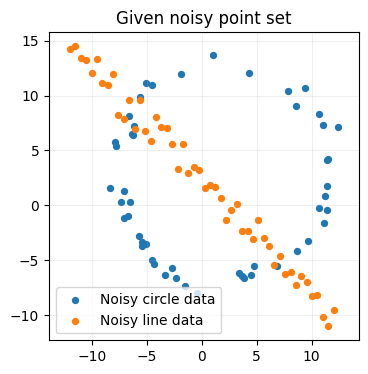

Shape of X: (100, 2)


In [3]:
np.random.seed(0)
N=100
half_n = N//2
r_gt=10.0
center_gt=np.array([2.0,3.0]); circle_noise=r_gt/16
angle=np.random.uniform(0,2*np.pi,half_n)
noise=circle_noise*np.random.randn(half_n)
X_circ=np.column_stack((center_gt[0]+(r_gt+noise)*np.cos(angle), center_gt[1]+(r_gt+noise)*np.sin(angle)))
slope_gt=-1.0; intercept_gt=2.0
x=np.linspace(-12,12,half_n)
y=slope_gt*x+intercept_gt+1.0*np.random.randn(half_n)
X_line=np.column_stack((x,y))
X=np.vstack([X_circ,X_line])

plt.figure(figsize=(4,4))
plt.scatter(X_circ[:,0],X_circ[:,1],s=18,label='Noisy circle data')
plt.scatter(X_line[:,0],X_line[:,1],s=18,label='Noisy line data')
plt.axis('equal'); plt.grid(alpha=0.2); plt.legend(); plt.title('Given noisy point set'); plt.show()
print('Shape of X:',X.shape)

## Q2(a) - Line fitting

I represent the line as $ax+by=d$, where $a^2+b^2=1$. This unit-normal condition is important because the error must be the actual perpendicular distance:

$$e_i=|ax_i+by_i-d|.$$

I randomly take **two points** to make each line candidate. I use a threshold of **1.5**, at least **30 inliers**, and **500 RANSAC trials**. These are suitable starting values for the noise used in the data generator. I choose the model with the largest inlier set. After this, I use total least squares on the inliers to get the final line.

In [4]:
def sample_line(points):
    vector = points[1]-points[0]
    length=np.linalg.norm(vector)
    if length < 1e-10: return None
    normal=np.array([-vector[1],vector[0]])/length
    distance = float(normal@points[0])
    if distance<0: normal, distance = -normal, -distance
    return (*normal, distance)

def line_residual(points, model):
    a,b,d=model
    return np.abs(a*points[:,0]+b*points[:,1]-d)

def fit_line_tls(points):
    mean=points.mean(axis=0)
    U=points-mean
    evals,evecs=np.linalg.eigh(U.T@U)
    normal=evecs[:,np.argmin(evals)]
    normal=normal/np.linalg.norm(normal)
    distance=float(normal@mean)
    if distance<0: normal, distance=-normal,-distance
    return (*normal, distance)

def ransac_line(points, threshold=1.5, min_inliers=30, iterations=500, rng=None):
    if rng is None: rng=np.random.default_rng(0)
    best=None
    for _ in range(iterations):
        sample_ids=rng.choice(len(points),2,replace=False)
        model=sample_line(points[sample_ids])
        if model is None: continue
        residuals=line_residual(points,model)
        inlier_mask=residuals<threshold
        count=np.count_nonzero(inlier_mask)
        if count<min_inliers: continue
        mse=float(np.mean(residuals[inlier_mask]**2))
        if best is None or count>best['count'] or (count==best['count'] and mse<best['mse']):
            best={'sample_ids':sample_ids.copy(),'sample_model':model,'raw_mask':inlier_mask,'count':count,'mse':mse}
    if best is None:raise RuntimeError('No line found')
    refined=fit_line_tls(points[best['raw_mask']])
    final_mask=line_residual(points,refined)<threshold
    refined=fit_line_tls(points[final_mask])
    final_mask=line_residual(points,refined)<threshold
    return {'sample_ids':best['sample_ids'],'sample_model':best['sample_model'],'model':refined,'mask':final_mask,'raw_count':best['count']}

## Q2(b) - Circle fitting

After removing the line inliers, I randomly select **three remaining points** to estimate the circle center $(c_x,c_y)$ and radius $r$. I reject samples that are almost collinear. The error is the distance of the point from the circle boundary:

$$e_i=\left|\sqrt{(x_i-c_x)^2+(y_i-c_y)^2}-r\right|.$$

I use a radial threshold of **1.25**, at least **26 inliers**, and **1500 trials**. Finally, I use `scipy.optimize.minimize` to minimize squared radial error on the selected circle inliers.

In [5]:
def sample_circle(points):
    p1,p2,p3=points
    A=2*np.array([p2-p1,p3-p1],dtype=float)
    B=np.array([p2@p2-p1@p1, p3@p3-p1@p1],dtype=float)
    if abs(np.linalg.det(A))<1e-5 or np.linalg.cond(A)>1e4:
        return None
    c=np.linalg.solve(A,B)
    r=float(np.linalg.norm(p1-c))
    if not (1.0<r<30.0):return None
    return (float(c[0]),float(c[1]),r)

def circle_residual(points,params):
    cx,cy,r=params
    return np.abs(np.linalg.norm(points-[cx,cy],axis=1)-r)

def fit_circle_optimized(points,init):
    def objective(v):
        distances=np.linalg.norm(points-v[:2],axis=1)
        return np.mean((distances-v[2])**2)
    result=minimize(objective, x0=np.asarray(init),method='L-BFGS-B',bounds=[(None,None),(None,None),(1e-5,None)])
    if not result.success:
        print('Optimizer:',result.message)
    return tuple(result.x)

def ransac_circle(points, threshold=1.25, min_inliers=26, iterations=1500, rng=None):
    if rng is None:rng=np.random.default_rng(1)
    best=None
    for _ in range(iterations):
        sample_ids=rng.choice(len(points),3,replace=False)
        model=sample_circle(points[sample_ids])
        if model is None:continue
        residuals=circle_residual(points,model)
        inlier_mask=residuals<threshold
        count=int(np.count_nonzero(inlier_mask))
        if count<min_inliers:continue
        mse=float(np.mean(residuals[inlier_mask]**2))
        if best is None or count>best['count'] or (count==best['count'] and mse<best['mse']):
            best={'sample_ids':sample_ids.copy(),'sample_model':model,'raw_mask':inlier_mask,'count':count,'mse':mse}
    if best is None:raise RuntimeError('No circle found: adjust threshold and min_inliers')
    refined=fit_circle_optimized(points[best['raw_mask']],best['sample_model'])
    final_mask=circle_residual(points,refined)<threshold
    refined=fit_circle_optimized(points[final_mask],refined)
    final_mask=circle_residual(points,refined)<threshold
    return {'sample_ids':best['sample_ids'],'sample_model':best['sample_model'],'model':refined,'mask':final_mask,'raw_count':best['count']}

## Q2(a) and Q2(b) - Run the two RANSAC methods

The normal-vector length printed below should be very close to one.

In [6]:
# Carefully chosen initial RANSAC settings
LINE_THRESHOLD = 1.5      # orthogonal distance in coordinate units
LINE_MIN_INLIERS = 30
CIRCLE_THRESHOLD = 1.25   # radial distance error
CIRCLE_MIN_INLIERS = 26

rng = np.random.default_rng(230727)
line = ransac_line(X, threshold=LINE_THRESHOLD,
                   min_inliers=LINE_MIN_INLIERS,
                   iterations=500, rng=rng)

# Subtract line consensus before fitting circle
remaining = X[~line['mask']]
circle = ransac_circle(remaining, threshold=CIRCLE_THRESHOLD,
                       min_inliers=CIRCLE_MIN_INLIERS,
                       iterations=1500, rng=rng)

a,b,d = line['model']
cx,cy,r = circle['model']
print(f'Line a={a:.4f}, b={b:.4f}, d={d:.4f}')
print(f'Unit normal norm = {np.hypot(a,b):.8f}')
print(f'Line inliers = {line["mask"].sum()} / {len(X)}')
print(f'Circle center = ({cx:.4f}, {cy:.4f}), radius = {r:.4f}')
print(f'Circle inliers = {circle["mask"].sum()} / {len(remaining)} remaining points')

Line a=0.7210, b=0.6930, d=1.5724
Unit normal norm = 1.00000000
Line inliers = 54 / 100
Circle center = (1.8982, 3.0101), radius = 9.8314
Circle inliers = 44 / 46 remaining points


## Q2(c) - Show both fitted models in one plot

The plot shows the full point set, line inliers, circle inliers, the random sample behind each selected model, the models from those samples, both final fitted models, and the true line and circle.

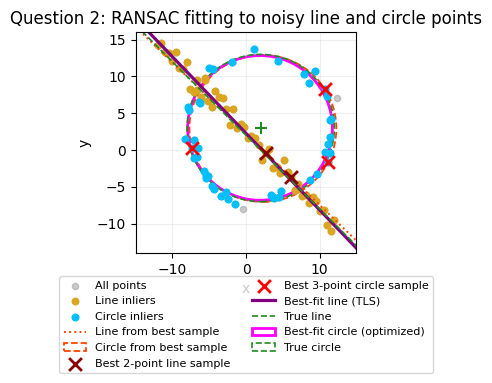

In [7]:
def plot_line(ax,model,x_limits,**kwargs):
    a,b,d=model
    if abs(b)>1e-10:
        xx=np.array(x_limits)
        yy=(d-a*xx)/b
        ax.plot(xx, yy,**kwargs)
    else:
        ax.axvline(d/a,**kwargs)

fig,ax=plt.subplots(figsize=(4,4))
ax.scatter(X[:,0],X[:,1],c='gray',alpha=0.4,s=20,label='All points',zorder=1)
ax.scatter(X[line['mask'],0],X[line['mask'],1],s=22,c='goldenrod',label='Line inliers',zorder=2)
ax.scatter(remaining[circle['mask'],0],remaining[circle['mask'],1],s=23,c='deepskyblue',label='Circle inliers',zorder=3)
plot_line(ax, sample_line(X[line['sample_ids']]), [-15,15], c='orangered', ls=':',lw=1.4, label='Line from best sample')
ax.add_patch(plt.Circle(circle['sample_model'][:2], circle['sample_model'][2],fill=False,ec='orangered',ls='--',lw=1.3,label='Circle from best sample'))
ax.scatter(X[line['sample_ids'],0],X[line['sample_ids'],1], marker='x',s=85,c='darkred',lw=2,label='Best 2-point line sample', zorder=5)
ax.scatter(remaining[circle['sample_ids'],0],remaining[circle['sample_ids'],1],marker='x',s=85,c='red',lw=2,label='Best 3-point circle sample',zorder=5)
plot_line(ax,line['model'],[-15,15],c='purple',lw=2.3,label='Best-fit line (TLS)')
plot_line(ax,(1/np.sqrt(2),1/np.sqrt(2),2/np.sqrt(2)),[-15,15],c='forestgreen',ls='--',lw=1.2,label='True line')
ax.add_patch(plt.Circle(circle['model'][:2],circle['model'][2],fill=False,ec='magenta',lw=2,label='Best-fit circle (optimized)'))
ax.add_patch(plt.Circle(center_gt,r_gt,fill=False,ec='forestgreen',ls='--',lw=1.2,label='True circle'))
ax.scatter(*center_gt,marker='+',c='forestgreen',s=65)
ax.set_xlim(-15,15);ax.set_ylim(-14,16);ax.set_aspect('equal',adjustable='box');ax.grid(alpha=0.2);ax.set_xlabel('x');ax.set_ylabel('y');ax.set_title('Question 2: RANSAC fitting to noisy line and circle points')
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.08), fontsize=8, ncol=2)
fig.tight_layout();fig.savefig(results_dir / 'q2_ransac_line_circle.png', dpi=200, bbox_inches='tight')
plt.show()
plt.close(fig)

## Q2(d) - What happens if the circle is fitted first?

I also repeat the experiment in the other order. This lets me compare the inlier numbers and fitted parameters instead of only guessing what might happen.

In [8]:
circle_first = ransac_circle(X, threshold=CIRCLE_THRESHOLD,
                             min_inliers=CIRCLE_MIN_INLIERS,
                             iterations=1500,
                             rng=np.random.default_rng(52))
remaining_after_circle = X[~circle_first['mask']]
line_second = ransac_line(remaining_after_circle,
                         threshold=LINE_THRESHOLD,
                         min_inliers=LINE_MIN_INLIERS,
                         iterations=500,
                         rng=np.random.default_rng(53))
print('LINE FIRST:')
print('  line inliers:',line['mask'].sum(), 'circle inliers:',circle['mask'].sum())
print('  fitted line (a,b,d):', np.round(line['model'],3))
print('  fitted circle (cx,cy,r):', np.round(circle['model'],3))
print('CIRCLE FIRST:')
print('  circle inliers:',circle_first['mask'].sum(),'line inliers:',line_second['mask'].sum())
print('  fitted circle (cx,cy,r):',np.round(circle_first['model'],3))
print('  fitted line (a,b,d):',np.round(line_second['model'],3))

LINE FIRST:
  line inliers: 54 circle inliers: 44
  fitted line (a,b,d): [0.721 0.693 1.572]
  fitted circle (cx,cy,r): [1.898 3.01  9.831]
CIRCLE FIRST:
  circle inliers: 57 line inliers: 41
  fitted circle (cx,cy,r): [1.902 3.018 9.88 ]
  fitted line (a,b,d): [0.723 0.691 1.664]


### Q2 - Results and answer

The run with the line fitted first gave these values:

| Quantity | True value | Estimated value |
|---|---:|---:|
| Line $a$ | 0.707 | 0.721 |
| Line $b$ | 0.707 | 0.693 |
| Line $d$ | 1.414 | 1.572 |
| Circle center $c_x$ | 2.000 | 1.898 |
| Circle center $c_y$ | 3.000 | 3.010 |
| Circle radius $r$ | 10.000 | 9.831 |

With **line first**, I obtained **54 line inliers** and **44 circle inliers**. With **circle first**, I obtained **57 circle inliers** and **41 line inliers**. In the circle-first run the estimated circle was approximately $(1.902,3.018)$ with radius $9.880$, and the line was approximately $(a,b,d)=(0.723,0.691,1.664)$.

Both orders gave values near the true models. The line-first result had a slightly better line distance $d$, while the circle-first radius was slightly closer to 10. When fitting the circle first, points near the line-circle crossings can join the circle consensus and be removed before fitting the line. This can reduce the line inlier count. **Fitting the circle first does not always fail**, but the result depends on the noise, thresholds and random samples.

---
# Question 3 - Homography and image overlay

### Method
For a point in one image and its corresponding point on the signboard,

$$\lambda\begin{bmatrix}x'\\y'\\1\end{bmatrix}=H\begin{bmatrix}x\\y\\1\end{bmatrix}.$$

I estimate the $3\times3$ homography $H$ from four corners, using `cv.getPerspectiveTransform()`. I use `cv.warpPerspective()` to move the poster into the signboard area. I then blend the warped poster with the photo using an alpha mask. The points are ordered **top-left, top-right, bottom-right, bottom-left**.

In [9]:
def read_image(path, preserve_alpha=False):
    mode = cv.IMREAD_UNCHANGED if preserve_alpha else cv.IMREAD_COLOR
    img = cv.imread(str(path), mode)
    if img is None:
        raise FileNotFoundError(f'Cannot load image: {path}')
    if img.ndim == 2:
        img = cv.cvtColor(img, cv.COLOR_GRAY2BGR)
    return img


def overlay_on_plane(background_bgr, overlay_bgr_or_bgra, dst_points, opacity=0.88):
    """Perspective warp an overlay and blend it onto a quadrilateral."""
    if not 0 <= opacity <= 1:
        raise ValueError('opacity must be between 0 and 1')

    pts = np.asarray(dst_points, dtype=np.float32)
    if pts.shape != (4, 2):
        raise ValueError('dst_points must be four (x,y) points')
    if abs(cv.contourArea(pts)) < 100:
        raise ValueError('Selected quadrilateral is too small or degenerate')

    bh, bw = background_bgr.shape[:2]
    oh, ow = overlay_bgr_or_bgra.shape[:2]

    # Corners ordered TL, TR, BR, BL
    src = np.float32([[0, 0], [ow-1, 0], [ow-1, oh-1], [0, oh-1]])
    H = cv.getPerspectiveTransform(src, pts)

    if overlay_bgr_or_bgra.shape[2] == 4:
        rgb_bgr = overlay_bgr_or_bgra[:, :, :3]
        alpha = overlay_bgr_or_bgra[:, :, 3]
    else:
        rgb_bgr = overlay_bgr_or_bgra[:, :, :3]
        alpha = np.full((oh, ow), 255, dtype=np.uint8)

    warped = cv.warpPerspective(rgb_bgr, H, (bw, bh), flags=cv.INTER_LINEAR)
    warped_alpha = cv.warpPerspective(alpha, H, (bw, bh), flags=cv.INTER_LINEAR)

    blend_alpha = (warped_alpha.astype(np.float32) / 255 * opacity)[:, :, None]
    final = np.clip(
        background_bgr.astype(np.float32) * (1 - blend_alpha)
        + warped.astype(np.float32) * blend_alpha,
        0, 255
    ).astype(np.uint8)

    corners_image = background_bgr.copy()
    cv.polylines(corners_image, [np.round(pts).astype(np.int32)], True, (0, 255, 0), 3)
    for number, (x, y) in enumerate(pts, 1):
        xy = (int(round(x)), int(round(y)))
        cv.circle(corners_image, xy, 5, (0, 0, 255), -1)
        cv.putText(corners_image, str(number), (xy[0] + 7, xy[1] - 7),
                   cv.FONT_HERSHEY_SIMPLEX, 0.7, (0, 255, 255), 2)

    return H, warped, warped_alpha, final, corners_image


def save_case(case_name, bg, overlay_img, points, opacity=0.88):
    H, warped, alpha, result, points_img = overlay_on_plane(
        bg, overlay_img, points, opacity=opacity
    )
    prefix = results_dir / f'q3_{case_name}'
    paths = {
        'corners': str(prefix) + '_corners.png',
        'warped': str(prefix) + '_warped.png',
        'final': str(prefix) + '_final.png',
        'comparison': str(prefix) + '_comparison.png',
        'homography': str(prefix) + '_H.txt',
        'points': str(prefix) + '_points.json',
    }
    cv.imwrite(paths['corners'], points_img)
    cv.imwrite(paths['warped'], warped)
    cv.imwrite(paths['final'], result)
    np.savetxt(paths['homography'], H, fmt='%.9f')
    Path(paths['points']).write_text(json.dumps(np.asarray(points).tolist(), indent=2))

    fig, axes = plt.subplots(1, 3, figsize=(13, 4))
    for ax, image, title in zip(
        axes, [bg, points_img, result],
        ['Original background', 'Selected four points', 'Warped + blended result']
    ):
        ax.imshow(cv.cvtColor(image, cv.COLOR_BGR2RGB))
        ax.set_title(title)
        ax.axis('off')
    fig.tight_layout()
    fig.savefig(paths['comparison'], dpi=160, bbox_inches='tight')
    plt.show()
    plt.close(fig)

    print('Homography matrix:\n', H)
    print('Results saved in:', results_dir)
    for label, path in paths.items(): print(f'  {label}: {path}')
    return H, paths

For each image pair, I manually select four points on the flat surface where I want to place the poster.

The four points are selected in this order:

1. Top-left
2. Top-right
3. Bottom-right
4. Bottom-left

I use these four points to calculate the homography matrix. The poster is then transformed using perspective warping and blended with the background image.

The selected coordinates, homography matrix, and final images are saved in the results folder.


In [10]:

def click_four_points(img):
    _, buf = cv.imencode('.jpg', img)
    encoded = base64.b64encode(buf).decode()

    js = f"""(async () => {{
        const im = new Image();
        im.src = 'data:image/jpeg;base64,{encoded}';
        await im.decode();

        const c = document.createElement('canvas');
        c.width = im.width;
        c.height = im.height;
        c.style.maxWidth = '100%';
        document.body.appendChild(c);

        const ctx = c.getContext('2d');
        ctx.drawImage(im, 0, 0);
        const pts = [];

        return await new Promise(done => {{
            c.onclick = e => {{
                const r = c.getBoundingClientRect();
                const x = (e.clientX-r.left)*c.width/r.width;
                const y = (e.clientY-r.top)*c.height/r.height;

                pts.push([x,y]);
                ctx.fillStyle = 'red';
                ctx.fillRect(x-3, y-3, 6, 6);

                if (pts.length === 4) done(pts);
            }};
        }});
    }})()"""

    return np.array(output.eval_js(js), dtype=np.float32)


### Run the homography for both image pairs

The code saves a comparison image, a picture with the four selected points, the warped image, the final blended image, the four point coordinates, and the homography matrix for each pair.


pair1: Select 4 corners
Top-left, Top-right, Bottom-right, Bottom-left
Selected points:
 [[164. 123.]
 [295. 163.]
 [310. 411.]
 [164. 403.]]


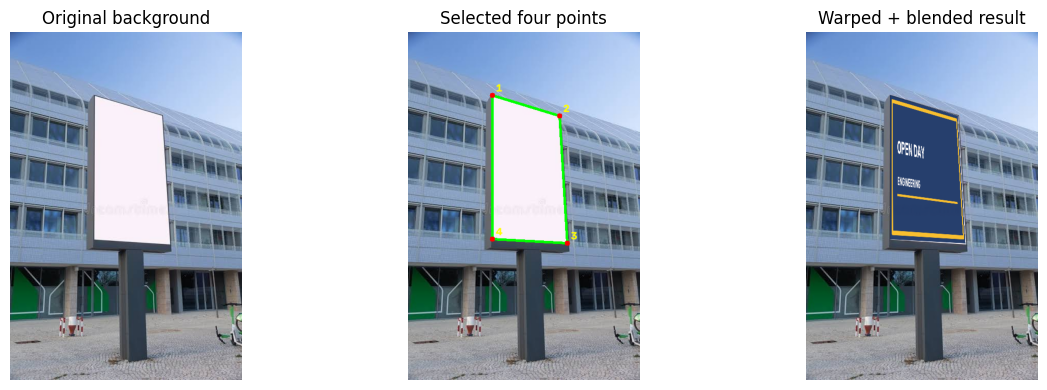

Homography matrix:
 [[ 2.12981256e-01 -4.25093029e-02  1.64000000e+02]
 [ 7.71516934e-02  5.19149182e-01  1.23000000e+02]
 [ 1.66190891e-04 -2.59203067e-04  1.00000000e+00]]
Results saved in: /content/drive/MyDrive/EN3160_Assignment_02/results
  corners: /content/drive/MyDrive/EN3160_Assignment_02/results/q3_pair1_corners.png
  warped: /content/drive/MyDrive/EN3160_Assignment_02/results/q3_pair1_warped.png
  final: /content/drive/MyDrive/EN3160_Assignment_02/results/q3_pair1_final.png
  comparison: /content/drive/MyDrive/EN3160_Assignment_02/results/q3_pair1_comparison.png
  homography: /content/drive/MyDrive/EN3160_Assignment_02/results/q3_pair1_H.txt
  points: /content/drive/MyDrive/EN3160_Assignment_02/results/q3_pair1_points.json

pair2: Select 4 corners
Top-left, Top-right, Bottom-right, Bottom-left
Selected points:
 [[171.       109.54999 ]
 [443.        63.549988]
 [446.       282.55    ]
 [168.       309.55    ]]


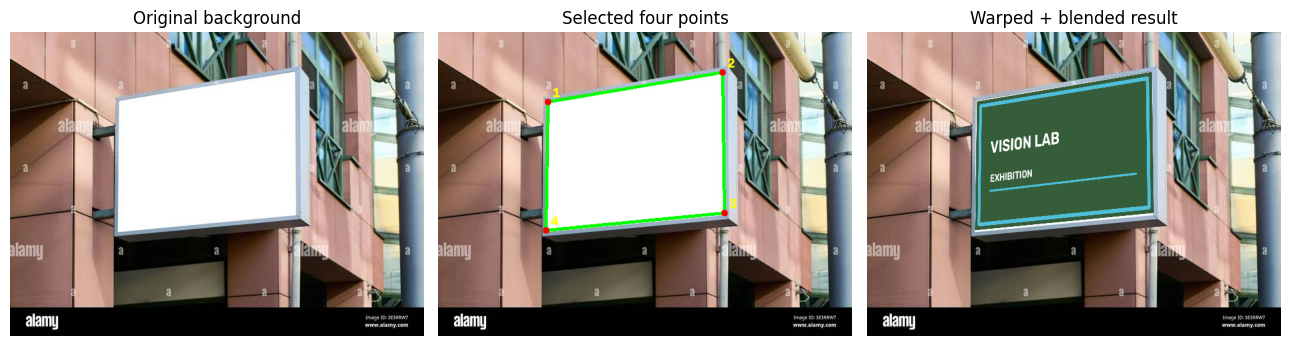

Homography matrix:
 [[ 2.90913730e-01 -1.43964427e-02  1.71000000e+02]
 [-6.46746162e-02  4.31219085e-01  1.09549988e+02]
 [-1.11764790e-04 -4.59221916e-05  1.00000000e+00]]
Results saved in: /content/drive/MyDrive/EN3160_Assignment_02/results
  corners: /content/drive/MyDrive/EN3160_Assignment_02/results/q3_pair2_corners.png
  warped: /content/drive/MyDrive/EN3160_Assignment_02/results/q3_pair2_warped.png
  final: /content/drive/MyDrive/EN3160_Assignment_02/results/q3_pair2_final.png
  comparison: /content/drive/MyDrive/EN3160_Assignment_02/results/q3_pair2_comparison.png
  homography: /content/drive/MyDrive/EN3160_Assignment_02/results/q3_pair2_H.txt
  points: /content/drive/MyDrive/EN3160_Assignment_02/results/q3_pair2_points.json


In [11]:


q3_pairs = [
    ('pair1', 'building_1.jpg', 'q3_poster1.png'),
    ('pair2', 'building_2.jpg', 'q3_poster2.png')
]

for case, bg_name, poster_name in q3_pairs:

    bg = read_image(images_dir / bg_name)
    poster = read_image(images_dir / poster_name)

    print(f"\n{case}: Select 4 corners")
    print("Top-left, Top-right, Bottom-right, Bottom-left")

    # Select four points manually
    points = click_four_points(bg)

    print("Selected points:\n", points)

    # Calculate homography and save result
    H, paths = save_case(
        case, bg, poster, points, opacity=0.88
    )



### Q3 - Result and discussion

For **Pair 1**, the Open Day poster follows the slanted edges of the upright signboard. For **Pair 2**, the Vision Lab poster follows the tilted top and bottom edges of the second signboard. In both results the image stays inside the four chosen points, and the other parts of the photograph remain unchanged.

The result depends on the selected points. If a corner is placed incorrectly, the poster may look stretched or shifted. The poster also looks flatter and cleaner than the actual photo because its original shading and reflections are not recreated by the warp. The second background image contains **stock-photo watermarks**. These belong to the background image and are not caused by the homography. A clean licensed photograph would be better for a final presentation.

**Answer:** Four corner pairs were enough to calculate a homography for each flat signboard. Perspective warping adjusted each poster to the surface; alpha blending combined it with the photo.

---
# Question 4 - PCB image alignment and differences

### Method

1. I resize the images to a maximum side of **1400 pixels** so the processing time is manageable.
2. I detect and describe keypoints using `cv.SIFT_create()`.
3. I use BFMatcher to find two nearest descriptor matches and retain a match when $d_1 < 0.78d_2$.
4. I fit an input-to-reference homography with `cv.findHomography(..., cv.RANSAC, 4.0)`.
5. I align the input image using `cv.warpPerspective()`.
6. I calculate `cv.absdiff()` between the aligned image and the reference. I ignore pixels outside the valid warped area.

The color heatmap is used **only to make the differences easier to see**. The grayscale difference and mean difference are calculated before that display enhancement.

In [12]:
reference_name = 'AECC1.jpg'
pcb_names = ['AECC2.jpg', 'AECC3.jpg', 'AECC4.jpg', 'ADAD1.jpg', 'AAAA1.jpg']

# SIFT + BFMatcher + RANSAC + perspective warp + difference image.
# The reduced working size makes Colab faster and keeps all outputs comparable.
MAX_SIDE = 1400
RATIO_TEST = 0.78          # Lowe nearest-neighbor ratio threshold
REPROJECTION_THRESHOLD = 4.0  # pixels in resized images
N_FEATURES = 8000        # More keypoints helps with AAAA1.jpg

sift = cv.SIFT_create(nfeatures=N_FEATURES, contrastThreshold=0.01, edgeThreshold=15)
matcher = cv.BFMatcher(cv.NORM_L2, crossCheck=False)


def read_resized(path, max_side=MAX_SIDE):
    im = cv.imread(str(path), cv.IMREAD_COLOR)
    if im is None:
        raise FileNotFoundError(str(path))
    h, w = im.shape[:2]
    scale = min(1.0, max_side / max(h, w))
    if scale < 1.0:
        im = cv.resize(im, (round(w*scale), round(h*scale)), interpolation=cv.INTER_AREA)
    return im


def make_compact_panel(reference, aligned, heatmap):
    # Each panel has the exact same registered width/height.
    target_height = 620
    def tile(img, title):
        h, w = img.shape[:2]
        nw = round(w * target_height / h)
        small = cv.resize(img, (nw, target_height), interpolation=cv.INTER_AREA)
        canvas = np.full((target_height+43, nw, 3), 255, dtype=np.uint8)
        canvas[43:, :] = small
        cv.putText(canvas, title, (12, 28), cv.FONT_HERSHEY_SIMPLEX,
                   0.7, (20,20,20), 2, cv.LINE_AA)
        return canvas
    return cv.hconcat([
        tile(reference, 'Reference AECC1'),
        tile(aligned, 'Aligned input'),
        tile(heatmap, 'Difference (enhanced)')
    ])


def run_q4_for_image(reference, ref_kps, ref_des, filename):
    name = Path(filename).stem
    moving = read_resized(images_dir / filename)
    mov_gray = cv.cvtColor(moving, cv.COLOR_BGR2GRAY)
    mov_kps, mov_des = sift.detectAndCompute(mov_gray, None)
    if mov_des is None or ref_des is None:
        raise ValueError(f'No SIFT descriptors: {filename}')

    # Input -> Reference matching, so H maps points in moving into AECC1.
    neighbor_pairs = matcher.knnMatch(mov_des, ref_des, k=2)
    good = [m for pair in neighbor_pairs if len(pair)==2
            for m,n in [pair] if m.distance < RATIO_TEST*n.distance]
    if len(good) < 4:
        raise ValueError(f'Only {len(good)} reliable feature matches for {filename}')

    source_pts = np.float32([mov_kps[m.queryIdx].pt for m in good]).reshape(-1,1,2)
    target_pts = np.float32([ref_kps[m.trainIdx].pt for m in good]).reshape(-1,1,2)
    H, inlier_mask = cv.findHomography(source_pts, target_pts, cv.RANSAC,
                                      REPROJECTION_THRESHOLD,
                                      maxIters=12000, confidence=0.999)
    if H is None or inlier_mask is None:
        raise ValueError(f'RANSAC homography failed for {filename}')
    inlier_mask = inlier_mask.ravel().astype(bool)
    n_inliers = int(inlier_mask.sum())
    if n_inliers < 15:
        raise ValueError(f'Only {n_inliers} homography inliers for {filename}')

    # Draw only RANSAC inlier matches, not mismatching/outlier correspondence lines.
    inlier_matches = [m for m, keep in zip(good, inlier_mask) if keep]
    inlier_matches = sorted(inlier_matches, key=lambda m: m.distance)[:70]
    matches_view = cv.drawMatches(moving, mov_kps, reference, ref_kps,
                                  inlier_matches, None,
                                  flags=cv.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)

    out_h, out_w = reference.shape[:2]
    aligned = cv.warpPerspective(moving, H, (out_w, out_h), flags=cv.INTER_LINEAR)
    valid = cv.warpPerspective(np.full(moving.shape[:2], 255, np.uint8),
                               H, (out_w, out_h), flags=cv.INTER_NEAREST)
    valid = cv.erode(valid, np.ones((5,5),np.uint8), iterations=1)
    valid_bool = valid > 0
    if not np.any(valid_bool):
        raise ValueError('Warped image does not overlap the reference.')

    # Difference = absolute pixel difference AFTER geometric alignment.
    raw_color_diff = cv.absdiff(reference, aligned)
    gray_diff = cv.cvtColor(raw_color_diff, cv.COLOR_BGR2GRAY)
    gray_diff[~valid_bool] = 0
    raw_color_diff[~valid_bool] = 0

    # A visualization-only heatmap. It boosts small intensities consistently.
    enhanced = cv.convertScaleAbs(gray_diff, alpha=3.0)
    heatmap = cv.applyColorMap(enhanced, cv.COLORMAP_JET)
    heatmap[~valid_bool] = (0,0,0)
    overlay = cv.addWeighted(reference, 0.5, aligned, 0.5, 0)
    overlay[~valid_bool] = reference[~valid_bool]
    comparison = make_compact_panel(reference, aligned, heatmap)

    # Reprojection error: smaller values mean inlier points align more closely.
    reproj = cv.perspectiveTransform(source_pts, H).reshape(-1,2)
    reproj_error = np.linalg.norm(reproj-target_pts.reshape(-1,2),axis=1)
    median_reproj = float(np.median(reproj_error[inlier_mask]))
    mean_gray_diff = float(gray_diff[valid_bool].mean())

    prefix = f'q4_{name}'
    cv.imwrite(str(results_dir / f'{prefix}_matches.png'), matches_view)
    cv.imwrite(str(results_dir / f'{prefix}_aligned.png'), aligned)
    cv.imwrite(str(results_dir / f'{prefix}_difference.png'), gray_diff)
    cv.imwrite(str(results_dir / f'{prefix}_difference_color.png'), raw_color_diff)
    cv.imwrite(str(results_dir / f'{prefix}_heatmap.png'), heatmap)
    cv.imwrite(str(results_dir / f'{prefix}_overlay.png'), overlay)
    cv.imwrite(str(results_dir / f'{prefix}_comparison.png'), comparison)
    cv.imwrite(str(results_dir / f'{prefix}_valid_mask.png'), valid)
    np.savetxt(str(results_dir / f'{prefix}_H.txt'), H, fmt='%.9f')

    return {
        'image': filename,
        'sift_features_reference': len(ref_kps),
        'sift_features_input': len(mov_kps),
        'good_matches': len(good),
        'ransac_inliers': n_inliers,
        'inlier_ratio': round(n_inliers/len(good), 3),
        'median_reprojection_error_px': round(median_reproj, 3),
        'valid_area_fraction': round(float(valid_bool.mean()), 3),
        'mean_abs_gray_difference': round(mean_gray_diff, 3),
        'difference_image': f'{prefix}_difference.png',
    }

reference = read_resized(images_dir / reference_name)
ref_gray = cv.cvtColor(reference, cv.COLOR_BGR2GRAY)
ref_kps, ref_des = sift.detectAndCompute(ref_gray, None)
assert ref_des is not None, 'Cannot detect reference SIFT descriptors.'
print('Reference image working size:', reference.shape[:2])
print('Reference keypoints:', len(ref_kps))

Reference image working size: (1400, 1181)
Reference keypoints: 8001


## Q4(a), Q4(b), Q4(c) and Q4(d) - Align all five PCB images

The code below runs the same method on every given image. It stores the matched-keypoint figure, transformed image, difference image, heatmap and homography. The table compares RANSAC inliers and average difference values.

In [13]:
# Run all five PCB comparisons.
records = []
for name in pcb_names:
    print('Processing:', name, flush=True)
    try:
        record = run_q4_for_image(reference, ref_kps, ref_des, name)
        records.append(record)
        print('  Good matches:', record['good_matches'],
              '| Inliers:', record['ransac_inliers'],
              '| Mean difference:', record['mean_abs_gray_difference'])
    except Exception as exc:
        print('  FAILED:', exc)
        records.append({'image': name, 'error': str(exc)})

summary = pd.DataFrame(records)
summary_file = results_dir / 'q4_summary.csv'
summary.to_csv(summary_file, index=False)
print('\nSummary saved:', summary_file)
display(summary)

Processing: AECC2.jpg
  Good matches: 3781 | Inliers: 3360 | Mean difference: 2.816
Processing: AECC3.jpg
  Good matches: 4466 | Inliers: 3982 | Mean difference: 2.53
Processing: AECC4.jpg
  Good matches: 3733 | Inliers: 3309 | Mean difference: 3.36
Processing: ADAD1.jpg
  Good matches: 573 | Inliers: 233 | Mean difference: 31.026
Processing: AAAA1.jpg
  Good matches: 123 | Inliers: 33 | Mean difference: 28.421

Summary saved: /content/drive/MyDrive/EN3160_Assignment_02/results/q4_summary.csv


,image,sift_features_reference,sift_features_input,good_matches,ransac_inliers,inlier_ratio,median_reprojection_error_px,valid_area_fraction,mean_abs_gray_difference,difference_image
0,AECC2.jpg,8001,8000,3781,3360,0.889,0.200,0.981,2.816,q4_AECC2_difference.png
1,AECC3.jpg,8001,8000,4466,3982,0.892,0.166,0.986,2.530,q4_AECC3_difference.png
2,AECC4.jpg,8001,8000,3733,3309,0.886,0.213,0.982,3.360,q4_AECC4_difference.png
3,ADAD1.jpg,8001,8000,573,233,0.407,0.438,0.978,31.026,q4_ADAD1_difference.png
4,AAAA1.jpg,8001,5322,123,33,0.268,0.947,0.888,28.421,q4_AAAA1_difference.png


### Visual comparison of the five difference images

These images show where each aligned PCB differs from the reference. The first three should have relatively weak differences. The last two differ more, and the image from `AAAA1.jpg` has a larger area outside the valid warp.

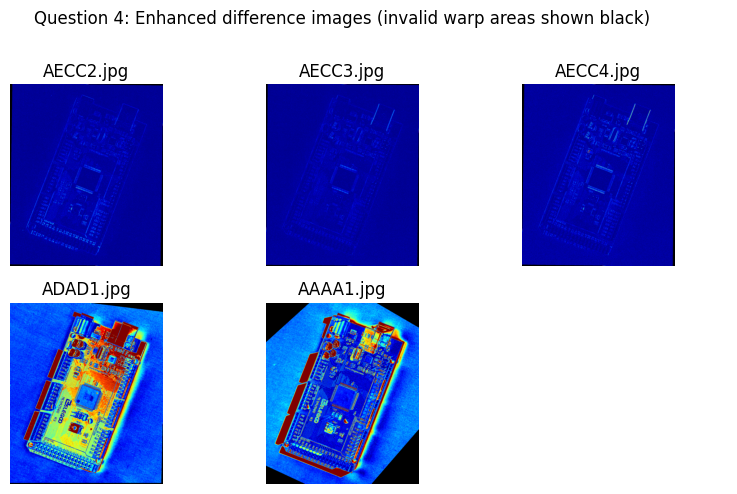

In [15]:
# All five difference images in one figure
fig, axes = plt.subplots(2, 3, figsize=(8, 5))
for ax, name in zip(axes.flat, pcb_names):
    heatmap_path = results_dir / f'q4_{Path(name).stem}_heatmap.png'
    heatmap = cv.imread(str(heatmap_path), cv.IMREAD_COLOR)
    if heatmap is None:
        ax.text(0.5, 0.5, 'Missing result', ha='center')
    else:
        ax.imshow(cv.cvtColor(heatmap, cv.COLOR_BGR2RGB))
    ax.set_title(name)
    ax.axis('off')
for ax in axes.flat[len(pcb_names):]:
    ax.axis('off')
fig.suptitle('Question 4: Enhanced difference images (invalid warp areas shown black)', y=0.98)
fig.tight_layout(rect=[0,0,1,0.97])
fig.savefig(results_dir / 'q4_all_difference_heatmaps.png', dpi=150, bbox_inches='tight')
plt.show()
plt.close(fig)

### Check the alignment and the SIFT matches

I include one easy case (`AECC2.jpg`) and one difficult case (`AAAA1.jpg`). The match lines are only those accepted by RANSAC, and the three-panel images show the reference, the aligned image, and the difference heatmap.

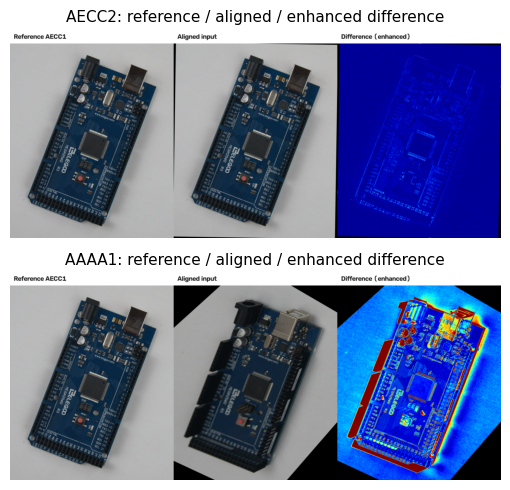

SIFT match images are saved as q4_AECC2_matches.png etc.


In [16]:
# One successful comparison and one more difficult comparison
fig, axes = plt.subplots(2, 1, figsize=(8, 5))
for ax, pcb in zip(axes, ['AECC2', 'AAAA1']):
    picture = cv.imread(str(results_dir / f'q4_{pcb}_comparison.png'))
    ax.imshow(cv.cvtColor(picture, cv.COLOR_BGR2RGB))
    ax.set_title(f'{pcb}: reference / aligned / enhanced difference', fontsize=11)
    ax.axis('off')
fig.tight_layout()
plt.show()
plt.close(fig)
print('SIFT match images are saved as q4_AECC2_matches.png etc.')

### Q4 - Results

These are the values saved in my Google Colab run. The last column is the average absolute grayscale difference over the **valid aligned area**, measured from 0 to 255.

| Input image | RANSAC inliers | Inlier ratio | Mean difference |
|---|---:|---:|---:|
| AECC2.jpg | 3,360 | 0.889 | 2.816 |
| AECC3.jpg | 3,982 | 0.892 | 2.530 |
| AECC4.jpg | 3,309 | 0.886 | 3.360 |
| ADAD1.jpg | 233 | 0.407 | 31.026 |
| AAAA1.jpg | 33 | 0.268 | 28.421 |

**AECC2, AECC3 and AECC4:** The PCB features line up closely with the template, and the difference values are small. **ADAD1:** The image can be aligned, but it looks different from the reference and has a much larger difference value. **AAAA1:** This is the hardest view. Only 33 RANSAC inliers were kept, and the valid-area fraction was about **0.888**. Its difference image is less reliable for judging individual parts because of the stronger viewpoint and appearance changes.

### Q4(e) - Why do the USB Type-B port, capacitors and reset button show high differences?

The homography mainly aligns points on the **flat PCB surface**. The USB socket, capacitors and reset button stand above the board. Their visible sides and tops move differently when the camera position changes. Because of this, they do not line up as well even when the flat board is aligned. Reflections on the metal, shadows, lighting and focus can make the differences larger.

A bright part of the difference image therefore **does not prove that a component is missing or faulty**. It may only be caused by the different camera angle or lighting. I would need a more controlled image to make a reliable fault decision.

---
# Conclusion

In **Question 1**, I used scale-normalized LoG to detect circle-like sunflower heads at different sizes. The dark-center and yellow-petal checks reduced unwanted detections, although some flowers were still missed.

In **Question 2**, my own RANSAC code found a line and a circle close to their true models, even with noisy points. The experiment also showed that fitting the models in a different order changes which points remain for the second fit.

In **Question 3**, homography allowed two posters to follow the perspective of two flat signboards. The shape depends on the four selected points.

In **Question 4**, SIFT matching and RANSAC were useful for aligning PCB images before comparing their pixels. The similar AECC boards had small differences. The more difficult views had larger differences, which should not be treated as defects without further checking.


**Code and commit history:** [GitHub repository](https://github.com/Pamodya-Wijesinghe/EN3160-Assignment-2-on-Fitting-and-Alignment)